Выбранная задача- классификация растений на кактусы, папоротники, розы, подсолнухи и тюльпаны
https://www.kaggle.com/datasets/artemgoncarov/plants-classification

Загрузим изображения и выведем 10 из них

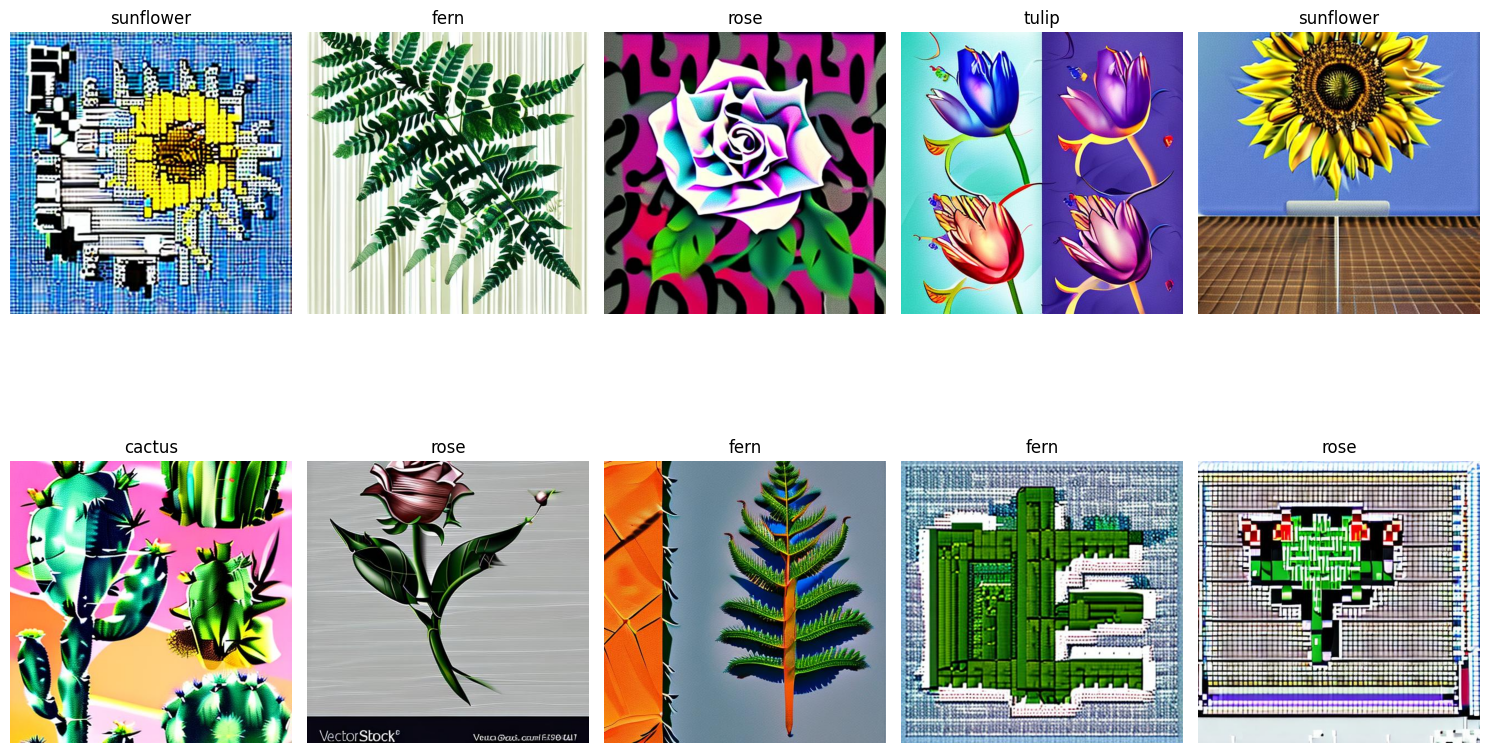

In [10]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

def load_images_from_folder(folder, target_size=(512, 512)):
    images = []
    labels = []
    for label in os.listdir(folder):
        if label in ['cactus', 'fern', 'rose', 'sunflower', 'tulip']:
            label_folder = os.path.join(folder, label)
            if os.path.isdir(label_folder):
                for filename in os.listdir(label_folder):
                    img_path = os.path.join(label_folder, filename)
                    img = cv2.imread(img_path)
                    if img is not None:
                        # Изменяем размер изображения
                        img_resized = cv2.resize(img, target_size)
                        images.append(img_resized)
                        labels.append(label)
    return images, labels

# Путь к папке с изображениями
folder_path = r"..\\static\\csv\\dataset\\train"
images, labels = load_images_from_folder(folder_path)

# Преобразуем в массивы
images = np.array(images)  
labels = np.array(labels)

# Получаем случайные индексы
num_images_to_display = min(10, len(images))
random_indices = np.random.choice(len(images), size=num_images_to_display, replace=False)

# Подготовка к визуализации
cols = 5
rows = num_images_to_display // cols + (num_images_to_display % cols > 0)

plt.figure(figsize=(15, 5 * rows))

for i, idx in enumerate(random_indices):
    plt.subplot(rows, cols, i + 1)
    plt.imshow(cv2.cvtColor(images[idx], cv2.COLOR_BGR2RGB))
    plt.title(labels[idx])
    plt.axis('off')

plt.tight_layout()
plt.show()

Применим методы предобработки: изменение размера, преобразование в оттенки серого и повышение контраста

In [16]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def preprocess_images(images):
    processed_images = []
    for img in images:
        # Изменение размера
        img_resized = cv2.resize(img, (128, 128))
        # Преобразование в оттенки серого
        img_gray = cv2.cvtColor(img_resized, cv2.COLOR_BGR2GRAY)
        # Увеличение контраста с помощью выравнивания гистограммы
        img_eq = cv2.equalizeHist(img_gray)
        processed_images.append(img_eq)
    return np.array(processed_images)

# Применяем обработку к набору изображений
processed_images = preprocess_images(images)

# Отображаем только одно изображение из обработанного набора
def display_single_image(original, processed, index):
    plt.figure(figsize=(10, 5))
    
    # Отображение оригинального изображения
    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(original[index], cv2.COLOR_BGR2RGB))
    plt.title('Оригинальное изображение')
    plt.axis('off')

    # Отображение обработанного изображения
    plt.subplot(1, 2, 2)
    plt.imshow(processed[index], cmap='gray')
    plt.title('Обработанное изображение')
    plt.axis('off')

    plt.show()



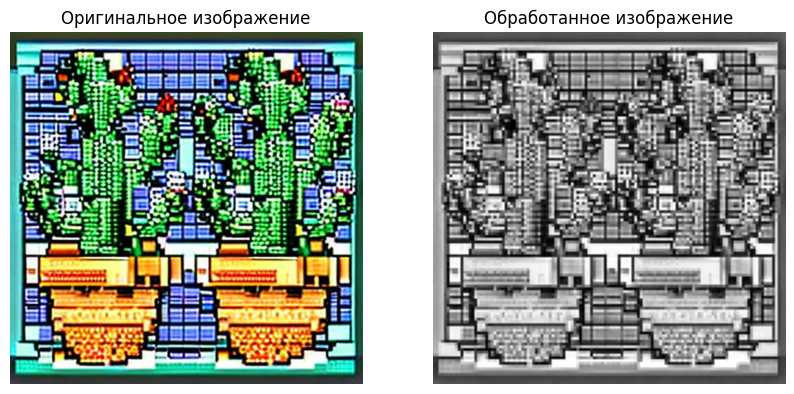

In [17]:
index = 155 
display_single_image(images, processed_images, index)

Проверим фильтрацию и восстановление изображений: удалим шумы с помощью размытия Гаусса, повысим резкость изображения с помощью ядра ,определим границы с помощью алгоритма Canny

In [14]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def apply_filters(img):
    # Удаление шумов
    img_blur = cv2.GaussianBlur(img, (5, 5), 0)
    # Повышение резкости
    kernel = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])
    img_sharp = cv2.filter2D(img_blur, -1, kernel)
    # Определение границ
    img_edges = cv2.Canny(img_sharp, 100, 200)
    return img_edges

def preprocess_images(images):
    processed_images = []
    for img in images:
        # Изменение размера
        img_resized = cv2.resize(img, (128, 128))
        # Преобразование в оттенки серого
        img_gray = cv2.cvtColor(img_resized, cv2.COLOR_BGR2GRAY)
        # Увеличение контраста с помощью выравнивания гистограммы
        img_eq = cv2.equalizeHist(img_gray)
        processed_images.append(img_eq)
    return np.array(processed_images)


# Выполнение предобработки изображений
processed_images = preprocess_images(images)

# Применяем фильтры к каждому изображению
filtered_images = np.array([apply_filters(img) for img in processed_images])

# Функция для отображения одного изображения
def display_single_image(original, processed, index):
    plt.figure(figsize=(10, 5))
    
    # Отображение оригинального изображения
    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(original[index], cv2.COLOR_BGR2RGB))
    plt.title('Оригинальное изображение')
    plt.axis('off')

    # Отображение обработанного изображения
    plt.subplot(1, 2, 2)
    plt.imshow(processed[index], cmap='gray')
    plt.title('Обработанное изображение')
    plt.axis('off')

    plt.show()



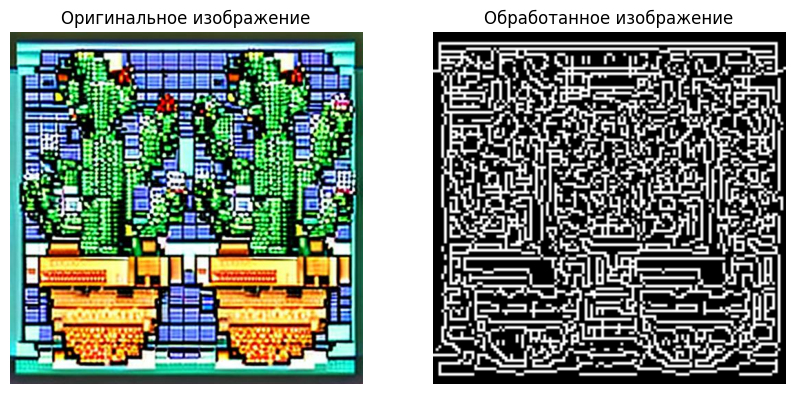

In [15]:
index = 155 
display_single_image(images, filtered_images, index)

Извлечём признаки с помощью функции для извлечения цветовых и текстурных признаков, извлечения среднего значения, стандартного отклонения и гистограммы для каждого цветового канала, а также характеристики Харалика для текстур

In [19]:
import os
import cv2
import numpy as np
import mahotas
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix

def load_images_from_folder(folder):
    images = []
    labels = []
    for label in os.listdir(folder):
        label_folder = os.path.join(folder, label)
        if os.path.isdir(label_folder):
            for filename in os.listdir(label_folder):
                img_path = os.path.join(label_folder, filename)
                img = cv2.imread(img_path)
                if img is not None:
                    img = cv2.resize(img, (512, 512))  
                    images.append(img)
                    labels.append(label)
    return images, labels

def extract_color_features(img):
    color_features = []
    for i in range(3):  # Для каждого канала B, G, R
        channel = img[:, :, i]
        mean = np.mean(channel)
        stddev = np.std(channel)
        hist = cv2.calcHist([channel], [0], None, [256], [0, 256]).flatten()
        color_features.extend([mean, stddev])
        color_features.extend(hist)
    return np.array(color_features)

def extract_texture_features(img):
    gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    haralick_features = mahotas.features.haralick(gray_img).mean(axis=0)
    return haralick_features

def extract_features(images):
    features = []
    for img in images:
        color_features = extract_color_features(img)
        texture_features = extract_texture_features(img)
        combined_features = np.hstack([color_features, texture_features])
        features.append(combined_features)
    return np.array(features)


data_folder = r"..\\static\\csv\\dataset\\train"
images, labels = load_images_from_folder(data_folder)

# Извлечение признаков для всех загруженных изображений
features_array = extract_features(images)

# Преобразование меток в массив NumPy
labels_array = np.array(labels)

# Разделение данных на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(features_array, labels_array, test_size=0.2, random_state=42)

# Обучение классификатора SVM
clf = SVC(kernel='linear')
clf.fit(X_train, y_train)

# Предсказание на тестовых данных
y_pred = clf.predict(X_test)

# Оценка результата
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))


[[30 15 14 10 11]
 [27 22  6 15 12]
 [10 13 19  8 14]
 [21 16  9 31  5]
 [14 10 24 12 16]]
              precision    recall  f1-score   support

      cactus       0.29      0.38      0.33        80
        fern       0.29      0.27      0.28        82
        rose       0.26      0.30      0.28        64
   sunflower       0.41      0.38      0.39        82
       tulip       0.28      0.21      0.24        76

    accuracy                           0.31       384
   macro avg       0.31      0.31      0.30       384
weighted avg       0.31      0.31      0.31       384



Обучим модель

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix

data_folder = r"..\\static\\csv\\dataset\\train"  
images, labels = load_images_from_folder(data_folder)
features_array = extract_features(images)  

# Преобразование меток в массив NumPy
labels_array = np.array(labels)

# Разделение данных на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(features_array, labels_array, test_size=0.2, random_state=42)

# Стандартизируем данные
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Обучаем классификатор SVM
model = SVC(kernel='linear', C=1)
model.fit(X_train, y_train)

# Предсказание на тестовых данных
y_pred = model.predict(X_test)

# Оценка качества
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[31 16  9 11 13]
 [21 29  9 13 10]
 [10 11 25  6 12]
 [21 10  8 33 10]
 [14  9 23 14 16]]
              precision    recall  f1-score   support

      cactus       0.32      0.39      0.35        80
        fern       0.39      0.35      0.37        82
        rose       0.34      0.39      0.36        64
   sunflower       0.43      0.40      0.42        82
       tulip       0.26      0.21      0.23        76

    accuracy                           0.35       384
   macro avg       0.35      0.35      0.35       384
weighted avg       0.35      0.35      0.35       384



Попробуем решить задачу на 10 рандомных картинках

In [ ]:
import numpy as np
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

def extract_color_features(img):
    color_features = []
    
    # Если изображение черно-белое (1 канал)
    if img.shape[-1] == 1:
        channel = img[:, :, 0]
        mean = np.mean(channel)
        stddev = np.std(channel)
        color_features.extend([mean, stddev])
    else:
        # Обрабатываем цветное изображение с 3 каналами (B, G, R)
        for i in range(3):
            channel = img[:, :, i]
            mean = np.mean(channel)
            stddev = np.std(channel)
            color_features.extend([mean, stddev])
    
    return np.array(color_features)

def extract_texture_features(img):
    return np.random.rand(5) 

def augment_data(images, labels):
    datagen = ImageDataGenerator(rotation_range=10,
                                 width_shift_range=0.1,
                                 height_shift_range=0.1,
                                 shear_range=0.1,
                                 zoom_range=0.1,
                                 horizontal_flip=True,
                                 fill_mode='nearest')

    augmented_images = []
    augmented_labels = []
    
    labels = np.array(labels)  # Преобразуем метки в numpy-массив
    
    for label in np.unique(labels):
        label_images = images[labels == label]
        if len(label_images) == 0:
            continue  # Пропускаем класс без изображений
        
        for img in label_images:
            if len(img.shape) == 2:  # Если чёрно-белое изображение
                img = np.expand_dims(img, axis=-1)  # (H, W) → (H, W, 1)
            
            img = img.reshape((1,) + img.shape)  # (1, H, W, C)
            for _ in range(10):  # Генерируем 10 аугментированных копий
                aug_iter = datagen.flow(img, batch_size=1)
                aug_img = next(aug_iter)[0].astype(np.uint8)
                augmented_images.append(aug_img.squeeze())  # Убираем лишние размерности
                augmented_labels.append(label)
    
    if len(augmented_images) == 0 or len(augmented_labels) == 0:
        raise ValueError("Ошибка: после аугментации нет изображений или меток.")
    
    return np.array(augmented_images), np.array(augmented_labels)

# Проверка входных данных
if len(processed_images) == 0 or len(labels) == 0:
    raise ValueError("Ошибка: входные данные пусты.")

# Аугментация данных
augmented_images, augmented_labels = augment_data(processed_images, labels)
print(f"Количество аугментированных изображений: {len(augmented_images)}")

# Извлечение признаков
augmented_features = []
for img in augmented_images:
    if len(img.shape) == 2:  # Чёрно-белые изображения
        img = np.expand_dims(img, axis=-1)  # (H, W) → (H, W, 1)
    
    color_features = extract_color_features(img)
    texture_features = extract_texture_features(img)
    combined_features = np.hstack([color_features, texture_features])
    
    augmented_features.append(combined_features)

augmented_features = np.array(augmented_features)
print(f"Размерность признаков: {augmented_features.shape}")

# Проверка признаков перед обучением
if len(augmented_features) == 0:
    raise ValueError("Ошибка: отсутствуют признаки для обучения.")

# Разделение данных
X_aug_train, X_aug_test, y_aug_train, y_aug_test = train_test_split(
    augmented_features, augmented_labels, test_size=0.1, random_state=42)

# Масштабирование признаков
scaler = StandardScaler()
X_aug_train = scaler.fit_transform(X_aug_train)
X_aug_test = scaler.transform(X_aug_test)

# Обучение модели (указываем, что модель должна быть определена заранее)
model.fit(X_aug_train, y_aug_train)

# Оценка качества модели
y_aug_pred = model.predict(X_aug_test)
print("Отчет по классификации:")
print(classification_report(y_aug_test, y_aug_pred))
print("Матрица ошибок:")
print(confusion_matrix(y_aug_test, y_aug_pred))



Количество аугментированных изображений: 19200
Размерность признаков: (19200, 7)
Отчет по классификации:
              precision    recall  f1-score   support

      cactus       0.20      0.21      0.20       368
        fern       0.25      0.30      0.28       388
        rose       0.27      0.20      0.23       421
   sunflower       0.23      0.22      0.23       372
       tulip       0.25      0.27      0.26       371

    accuracy                           0.24      1920
   macro avg       0.24      0.24      0.24      1920
weighted avg       0.24      0.24      0.24      1920

Матрица ошибок:
[[ 77  82  60  70  79]
 [ 84 117  57  59  71]
 [ 80  89  86  77  89]
 [ 84  96  50  82  60]
 [ 62  76  69  62 102]]
